# Cartagena 2: agua salada con longitud de arco

Importamos librerías

In [1]:
from spectral import *
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

Cargamos la imagen

In [2]:
ruta="../datos/cartagena2"
img=open_image(ruta+"/imagen/cartagena2.hdr")
arr=np.asarray(img.load())
arr.shape

(750, 750, 380)

Normalizamos el arreglo con la imagen

In [3]:
maximo=np.max(arr)
minimo=np.min(arr)
arr_norm=(arr-minimo)/(maximo-minimo)

Marcamos los píxeles que sí tienen datos. Las zonas negras de la imagen están en cero en todas las bandas y no se deben usar ni pintar

In [4]:
con_datos=np.max(arr,axis=2)>0
print("Píxeles sin datos:", np.sum(~con_datos))

Píxeles sin datos: 14517


Imagen base para dibujar

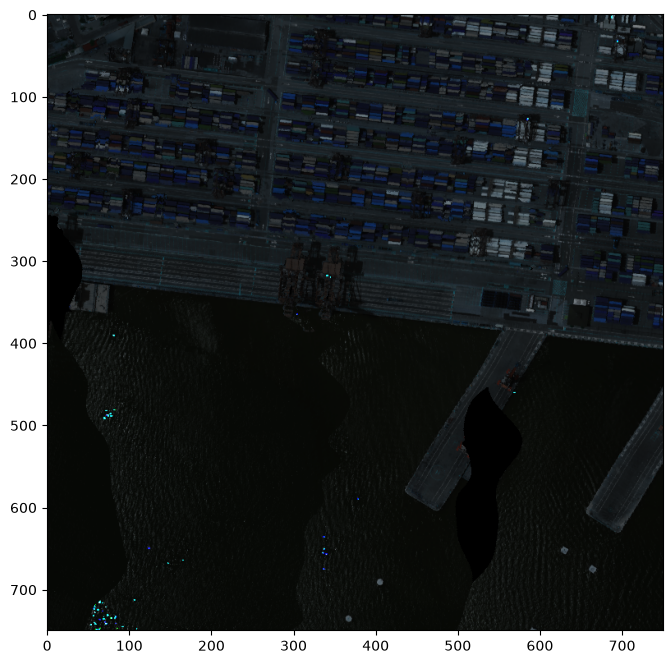

In [5]:
#Esta imagen no trae png: la armamos con las bandas (29, 50, 70), las mismas del original
imagen=(get_rgb(img,(29,50,70))*255).astype(np.uint8)
plt.figure(figsize=(8, 8))
plt.imshow(imagen)
plt.show()

Definimos la función de longitud de arco y el método de similitud (iguales al original)

In [6]:
def long_arco(R):
  return np.sum(np.abs(np.diff(R)))

def similitud_porcentual(A, B):
  A, B = np.array(A), np.array(B)
  #Similitud por posición: 100 si iguales, 0 si muy distintos
  sims = 100 * (1 - np.abs(A - B) / (np.abs(A) + np.abs(B) + 1e-9))
  return np.mean(sims)

# Recuadros de muestra
Los recuadros (x1, y1, x2, y2) se marcan a mano con `herramientas/marcar_recuadros.py` y se guardan en `datos/cartagenaN/recuadros/`.
Cada material tiene su archivo, y `otros.csv` tiene lo que seguro **no** es ninguno de los materiales.

In [7]:
recuadros={}
recuadros["agua_salada"]=pd.read_csv(ruta+"/recuadros/agua_salada.csv")
recuadros_otros=pd.read_csv(ruta+"/recuadros/otros.csv")
for nombre in recuadros:
  print(nombre, ":", len(recuadros[nombre]), "recuadros")
print("otros :", len(recuadros_otros), "recuadros")

agua_salada : 3 recuadros
otros : 3 recuadros


Dibujamos los recuadros (cian = materiales, rojo = otros)

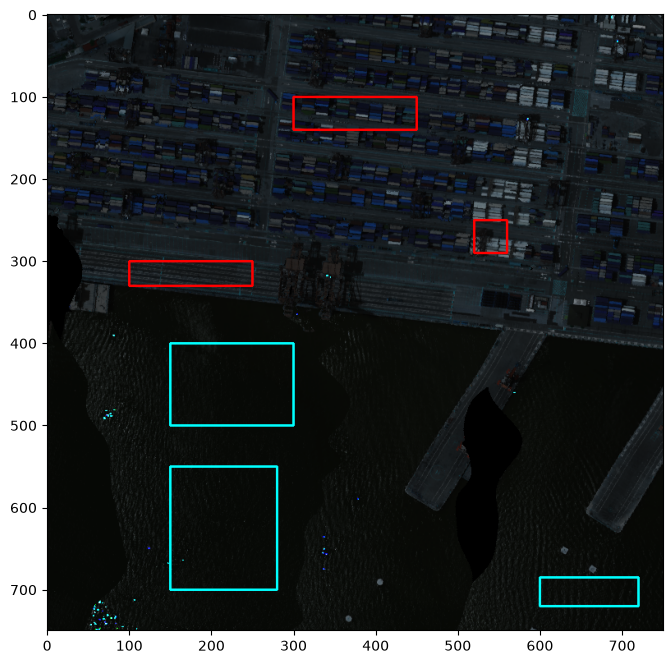

In [8]:
img_copy=imagen.copy()
for nombre in recuadros:
  for id,r in recuadros[nombre].iterrows():
    cv2.rectangle(img_copy, (r.x1,r.y1), (r.x2,r.y2), (0,255,255), 2)
for id,r in recuadros_otros.iterrows():
  cv2.rectangle(img_copy, (r.x1,r.y1), (r.x2,r.y2), (255,0,0), 2)
plt.figure(figsize=(8, 8))
plt.imshow(img_copy)
plt.show()

Función para sacar los píxeles (con datos) que hay dentro de unos recuadros

In [9]:
def pixeles_de(rec):
  l_pix=[]
  for id,r in rec.iterrows():
    for y in range(r.y1,r.y2):
      for x in range(r.x1,r.x2):
        if(con_datos[y][x]):
          l_pix.append((x,y))
  return pd.DataFrame(l_pix, columns=["x","y"])

In [10]:
#Aquí se guardan los mapas de similitud y umbrales de cada material
mapas={}
umbrales={}

# Material 1: agua salada

Sacamos los píxeles de los recuadros: agua salada (si) y otros (no). Tomamos 250 de cada uno al azar, como en el original

In [11]:
df_si=pixeles_de(recuadros["agua_salada"])
df_no=pixeles_de(recuadros_otros)
print("Píxeles de agua salada:", len(df_si), " otros:", len(df_no))
df_si=df_si.sample(n=min(250,len(df_si)),random_state=42)
df_no=df_no.sample(n=min(250,len(df_no)),random_state=42)
punt_si=df_si[["x","y"]].astype(int).to_numpy()
punt_no=df_no[["x","y"]].astype(int).to_numpy()
print("Usados:", len(punt_si), len(punt_no))

Píxeles de agua salada: 38698  otros: 12100
Usados: 250 250


Dibujamos los puntos sobre la imagen (rojo = agua salada, azul = otros)

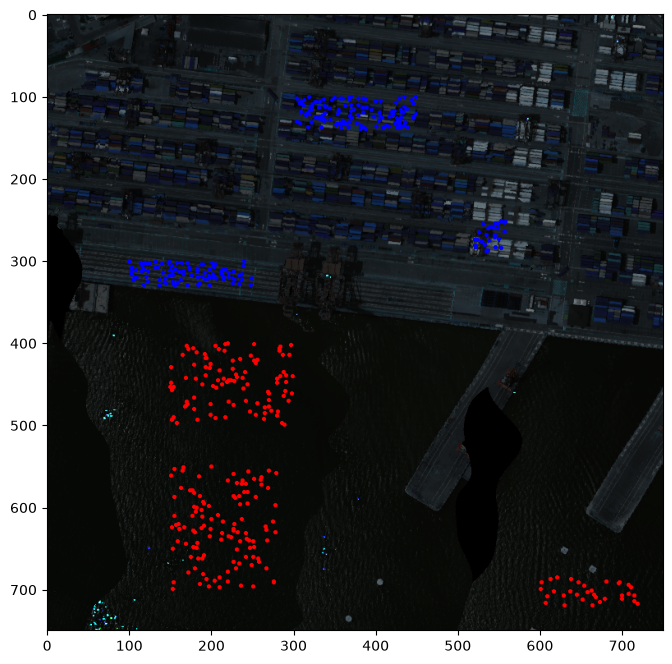

In [12]:
img_copy=imagen.copy()
for (x, y) in punt_si:
    cv2.circle(img_copy, (x, y), 1, (255, 0, 0), 2)
for (x, y) in punt_no:
    cv2.circle(img_copy, (x, y), 1, (0, 0, 255), 2)
plt.figure(figsize=(8, 8))
plt.imshow(img_copy)
plt.show()

Sacamos las firmas espectrales de cada punto y las dibujamos

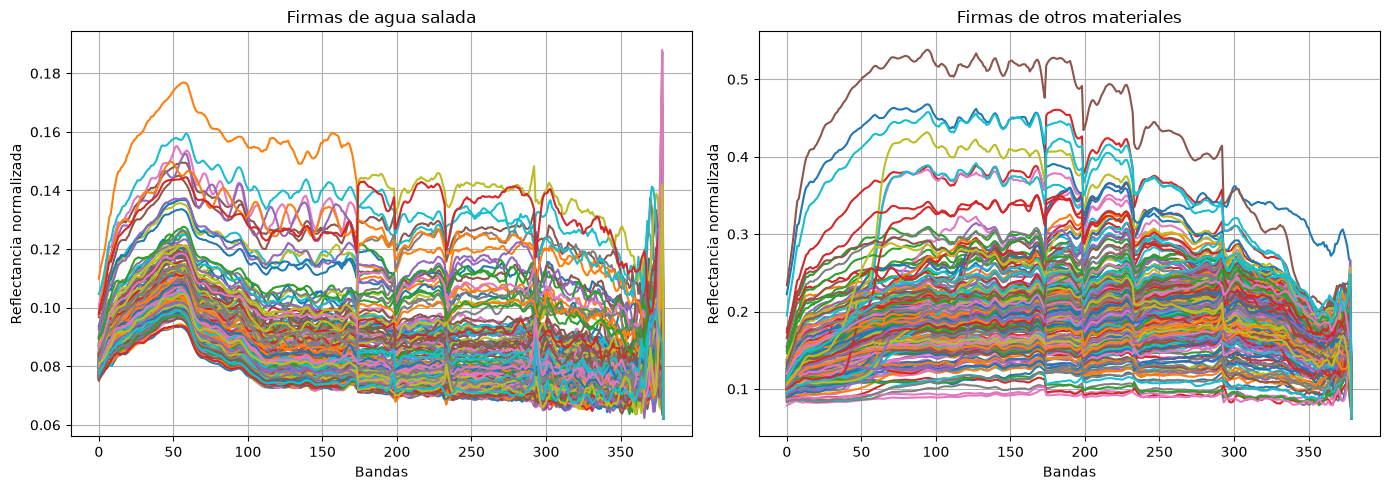

In [13]:
l_pix_si=[]
l_pix_no=[]
for pix in punt_si:
  l_pix_si.append(arr_norm[pix[1],pix[0],:])
for pix in punt_no:
  l_pix_no.append(arr_norm[pix[1],pix[0],:])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lista, titulo) in zip(axes, [(l_pix_si, "Firmas de agua salada"), (l_pix_no, "Firmas de otros materiales")]):
    for pix in lista:
        ax.plot(pix)
    ax.set_xlabel("Bandas")
    ax.set_ylabel("Reflectancia normalizada")
    ax.set_title(titulo)
    ax.grid(True)
plt.tight_layout()
plt.show()

Creamos el dataset (1 = agua salada, 0 = otro), lo desordenamos y lo partimos en entrenamiento y prueba

In [14]:
firmas=np.concatenate([l_pix_si, l_pix_no])
etiquetas=[1]*len(l_pix_si) + [0]*len(l_pix_no)
df=pd.DataFrame(firmas)
df['label']=etiquetas
df=df.sample(frac=1, random_state=42).reset_index(drop=True)

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df['label'],
    random_state=42
)
df_train.shape

(400, 381)

Calculamos el pixel promedio (mediana) del material y de los otros

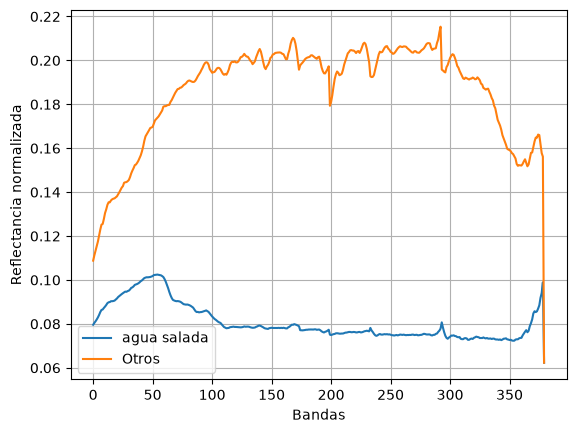

In [15]:
firm_si_train=df_train[df_train['label']==1].drop(columns='label').to_numpy()
firm_no_train=df_train[df_train['label']==0].drop(columns='label').to_numpy()
pix_prom_train=np.median(firm_si_train, axis=0)
pix_prom_no=np.median(firm_no_train, axis=0)
plt.plot(pix_prom_train, label="agua salada")
plt.plot(pix_prom_no, label="Otros")
plt.xlabel("Bandas")
plt.ylabel("Reflectancia normalizada")
plt.legend()
plt.grid()
plt.show()

Longitud de arco por tramos de 55 bandas, para ver en qué tramos se diferencian más

0 - 55  material: 0.0231  otros: 0.0652
55 - 110  material: 0.0253  otros: 0.0358
110 - 165  material: 0.0072  otros: 0.0455
165 - 220  material: 0.0121  otros: 0.087
220 - 275  material: 0.0115  otros: 0.0494
275 - 330  material: 0.0227  otros: 0.0672


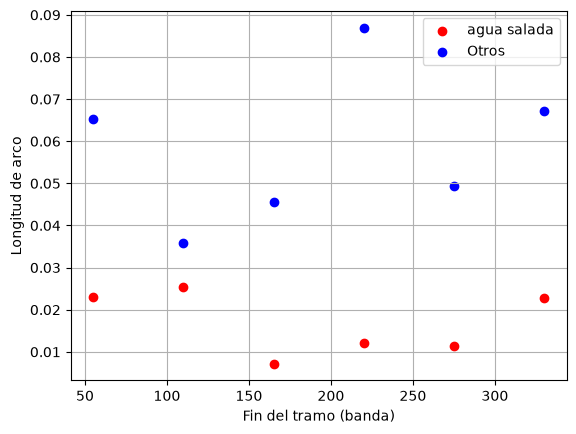

In [16]:
for i in range(55,381,55):
  s_si=long_arco(pix_prom_train[i-55:i])
  s_no=long_arco(pix_prom_no[i-55:i])
  plt.scatter(i, s_si, color="red")
  plt.scatter(i, s_no, color="blue")
  print(i-55,"-",i, " material:", round(s_si,4), " otros:", round(s_no,4))
plt.scatter([], [], color="red", label="agua salada")
plt.scatter([], [], color="blue", label="Otros")
plt.xlabel("Fin del tramo (banda)")
plt.ylabel("Longitud de arco")
plt.legend()
plt.grid()
plt.show()

Definimos los límites de los 2 tramos y la longitud de arco del pixel promedio

In [17]:
lim1=40
lim2=140
lim3=150
lim4=270
s1=long_arco(pix_prom_train[lim1:lim2])
s2=long_arco(pix_prom_train[lim3:lim4])
arr_s_prom=np.asarray([s1,s2])
print(arr_s_prom)

[0.03278738 0.02462968]


Probamos con las firmas del material para sacar el umbral (la similitud mínima, como en el original)

In [18]:
l_arc_si=[]
for id,row in df_train.iterrows():
  if(row['label']==1):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_si.append(sim)
umbral=round(np.min(l_arc_si),3)
print("Min", umbral)
print("Max", round(np.max(l_arc_si),3))

Min 32.371
Max 98.524


Probamos con las firmas de otros materiales

In [19]:
l_arc_no=[]
cont=0
for id,row in df_train.iterrows():
  if(row['label']==0):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_no.append(sim)
    if(sim<umbral):
      cont+=1
print("Otros bien separados:", cont, "de", len(l_arc_no))
print("Min", round(np.min(l_arc_no),3))
print("Max", round(np.max(l_arc_no),3))

Otros bien separados: 34 de 200
Min 13.763
Max 74.131


Probamos el método con el conjunto de prueba y calculamos las métricas

In [20]:
predicciones=[]
for id,row in df_test.iterrows():
  pix=np.asarray(row[0:380])
  long_arco1=long_arco(pix[lim1:lim2])
  long_arco2=long_arco(pix[lim3:lim4])
  arr_s_pix=np.asarray([long_arco1,long_arco2])
  sim=similitud_porcentual(arr_s_prom,arr_s_pix)
  if(sim>=umbral):
    predicciones.append(1)
  else:
    predicciones.append(0)
df_test['pred']=predicciones

y_true = df_test['label']
y_pred = df_test['pred']
print("Accuracy :", round(accuracy_score(y_true, y_pred),3))
print("Precision:", round(precision_score(y_true, y_pred),3))
print("Recall   :", round(recall_score(y_true, y_pred),3))
print("F1-score :", round(f1_score(y_true, y_pred),3))
print("\nMatriz de confusión:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.56
Precision: 0.532
Recall   : 1.0
F1-score : 0.694

Matriz de confusión:
[[ 6 44]
 [ 0 50]]


Desplegamos el método sobre la imagen. Guardamos la similitud de cada píxel en `mapa` para usarla al final

Porcentaje de agua salada: 87.888 %


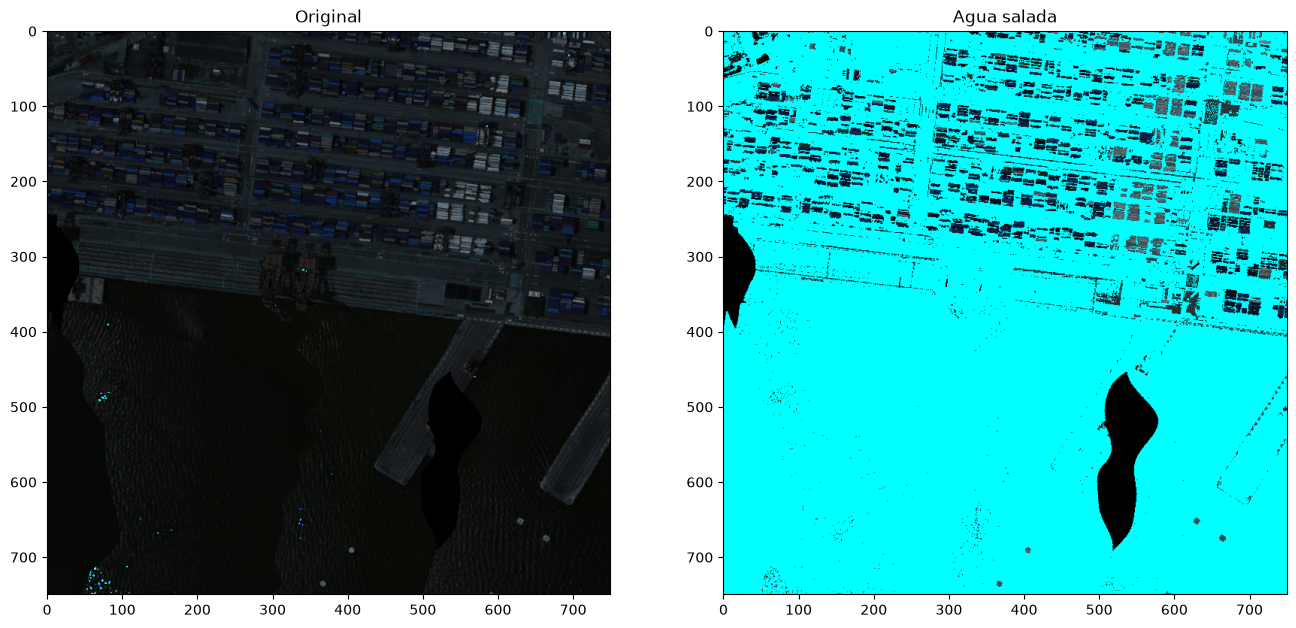

In [21]:
img_marcada=imagen.copy()
tam=arr_norm.shape
mapa=np.zeros((tam[0],tam[1]))
cont_pix=0
for i in range(tam[0]):
  for j in range(tam[1]):
    if(not con_datos[i][j]):
      continue
    #Obtenemos el pixel i,j de la imagen
    pix=arr_norm[i][j]
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    mapa[i][j]=sim
    if(sim>=umbral):
      img_marcada[i][j]=(0, 255, 255)
      cont_pix+=1
porc_pix_arc=(cont_pix/(tam[0]*tam[1]))*100
print("Porcentaje de agua salada:", round(porc_pix_arc,3),"%")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(imagen)
axes[0].set_title("Original")
axes[1].imshow(img_marcada)
axes[1].set_title("Agua salada")
plt.show()
plt.imsave("../resultados/cartagena2_agua_salada.png", img_marcada)

#Guardamos lo de este material para la imagen final
mapas["agua_salada"]=mapa
umbrales["agua_salada"]=umbral